# 02 — Model Experiments: So sánh 3 Thí nghiệm Xử lý Dữ liệu Trùng lặp
**Dự án:** Medical Chatbot — Phân loại bệnh dựa trên triệu chứng (ML Core)

Notebook này thực hiện huấn luyện và so sánh các mô hình Machine Learning cổ điển (Classical ML: Logistic Regression, Multinomial Naive Bayes, Random Forest) trên 3 tập dữ liệu đã chuẩn bị:
- **Exp 1 (Full):** Giữ nguyên toàn bộ dataset (173,219 mẫu train).
- **Exp 2 (Dedup):** Loại bỏ hoàn toàn trùng lặp (132,783 mẫu train).
- **Exp 3 (Capped K=3):** Giới hạn số lần lặp tối đa 3 lần (166,308 mẫu train).

**ĐIỂM QUAN TRỌNG:** Cả 3 thí nghiệm đều được đánh giá trên **cùng một tập Test độc lập (28,432 mẫu)** và **cùng tập Validation (28,432 mẫu)** để đảm bảo tính công bằng và loại bỏ hoàn toàn Data Leakage.

In [1]:
import os
import json
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, top_k_accuracy_score, classification_report

pd.set_option('display.max_columns', 30)
plt.style.use('seaborn-v0_8-whitegrid')

PROCESSED_DIR = os.path.join('..', 'data', 'processed')
if not os.path.exists(PROCESSED_DIR):
    PROCESSED_DIR = os.path.join('data', 'processed')

with open(os.path.join(PROCESSED_DIR, 'experiments_manifest.json'), 'r', encoding='utf-8') as f:
    manifest = json.load(f)

pd.DataFrame(manifest).T[['description', 'train_samples', 'val_samples', 'test_samples']]

,description,train_samples,val_samples,test_samples
exp1_full,Exp 1: Full Dataset (No Deduplication),173219,28432,28432
exp2_dedup,Exp 2: Fully Deduplicated Dataset,132783,28432,28432
exp3_capped,Exp 3: Frequency Capped Dataset (K=3),166308,28432,28432


## 1. Hàm huấn luyện và đánh giá chuẩn hóa
Đánh giá đồng thời:
- **Top-1 Accuracy:** Tỷ lệ dự đoán chính xác tuyệt đối ở vị trí đầu tiên.
- **Top-3 Accuracy:** Bệnh thực tế nằm trong top 3 gợi ý có xác suất cao nhất của mô hình.
- **Top-5 Accuracy:** Bệnh thực tế nằm trong top 5 gợi ý có xác suất cao nhất.

In [2]:
def evaluate_experiment(exp_id: str, model_type: str = 'nb'):
    exp_path = os.path.join(PROCESSED_DIR, exp_id)
    print(f'\n========== ĐANG HUẤN LUYỆN: {exp_id} ({model_type.upper()}) ==========')
    
    # 1. Tải dữ liệu
    t0 = time.time()
    train_df = pd.read_csv(os.path.join(exp_path, 'train.csv'))
    val_df = pd.read_csv(os.path.join(exp_path, 'val.csv'))
    
    feature_cols = [c for c in train_df.columns if c != 'diseases']
    X_train = train_df[feature_cols].values
    y_train = train_df['diseases'].values
    X_val = val_df[feature_cols].values
    y_val = val_df['diseases'].values
    
    # 2. Khởi tạo mô hình
    if model_type == 'nb':
        model = MultinomialNB(alpha=0.1)
    elif model_type == 'lr':
        model = LogisticRegression(max_iter=200, solver='saga', n_jobs=-1, random_state=42)
    else:
        raise ValueError(f'Unknown model: {model_type}')
        
    # 3. Fit mô hình
    fit_t0 = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - fit_t0
    
    # 4. Dự đoán xác suất trên Validation set
    proba_val = model.predict_proba(X_val)
    preds_val = model.predict(X_val)
    
    # 5. Tính metrics
    top1 = accuracy_score(y_val, preds_val)
    top3 = top_k_accuracy_score(y_val, proba_val, k=3, labels=model.classes_)
    top5 = top_k_accuracy_score(y_val, proba_val, k=5, labels=model.classes_)
    
    res = {
        'Experiment': exp_id,
        'Model': model_type.upper(),
        'Train Size': len(train_df),
        'Fit Time (s)': round(fit_time, 2),
        'Val Top-1 Acc': round(top1 * 100, 2),
        'Val Top-3 Acc': round(top3 * 100, 2),
        'Val Top-5 Acc': round(top5 * 100, 2)
    }
    print(f'Kết quả: Top-1: {res["Val Top-1 Acc"]}%, Top-3: {res["Val Top-3 Acc"]}%, Top-5: {res["Val Top-5 Acc"]}% (Fit: {fit_time:.2f}s)')
    return res

# Chạy kiểm thử nhanh trên mô hình Multinomial Naive Bayes cho cả 3 thí nghiệm
results = []
for exp in ['exp1_full', 'exp2_dedup', 'exp3_capped']:
    results.append(evaluate_experiment(exp, model_type='nb'))
    
res_df = pd.DataFrame(results)
res_df


========== ĐANG HUẤN LUYỆN: exp1_full (NB) ==========
Kết quả: Top-1: 83.7%, Top-3: 94.97%, Top-5: 97.49% (Fit: 504.23s)

========== ĐANG HUẤN LUYỆN: exp2_dedup (NB) ==========
Kết quả: Top-1: 82.46%, Top-3: 94.44%, Top-5: 97.14% (Fit: 364.75s)

========== ĐANG HUẤN LUYỆN: exp3_capped (NB) ==========
Kết quả: Top-1: 83.61%, Top-3: 94.92%, Top-5: 97.43% (Fit: 481.57s)


,Experiment,Model,Train Size,Fit Time (s),Val Top-1 Acc,Val Top-3 Acc,Val Top-5 Acc
0,exp1_full,NB,173219,504.23,83.70,94.97,97.49
1,exp2_dedup,NB,132783,364.75,82.46,94.44,97.14
2,exp3_capped,NB,166308,481.57,83.61,94.92,97.43


## 2. Trực quan hóa so sánh hiệu năng 3 thí nghiệm

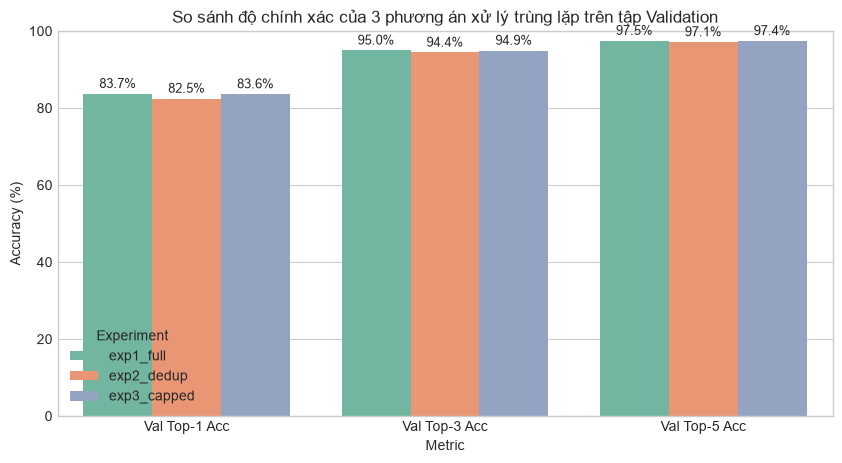

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
res_melted = res_df.melt(id_vars=['Experiment'], value_vars=['Val Top-1 Acc', 'Val Top-3 Acc', 'Val Top-5 Acc'], var_name='Metric', value_name='Accuracy (%)')
sns.barplot(data=res_melted, x='Metric', y='Accuracy (%)', hue='Experiment', palette='Set2', ax=ax)
plt.title('So sánh độ chính xác của 3 phương án xử lý trùng lặp trên tập Validation')
plt.ylim(0, 100)
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() + 1.5), ha='center', fontsize=9)
plt.show()